In [69]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report,confusion_matrix
from imblearn.combine import SMOTETomek
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Dropout,BatchNormalization
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
from joblib import dump

In [2]:
df = pd.read_csv('../Datasets/tb_dataset.csv')
df.head()

,Patient_ID,Age,Gender,BMI,Smoking,Alcohol_Use,HIV,Diabetes,Previous_TB,Household_TB_Contact,...,Weight_Loss,Fatigue,Appetite_Loss,Oxygen_Saturation,ESR,WBC_Count,Chest_Xray_Result,GeneXpert_Result,Socioeconomic_Status,TB
0,12696,18,Male,NaN,No,No,No,No,No,No,...,NaN,NaN,No,NaN,NaN,NaN,NaN,NaN,High,No
1,10762,41,Female,21.9,No,No,No,No,No,No,...,No,Mild,No,93.5,20.4,4665.0,Suspicious,Inconclusive,High,Yes
2,51703,45,Male,29.5,No,No,No,No,Yes,No,...,No,Moderate,No,97.2,54.9,5343.0,Normal,Negative,Middle,No
3,47037,55,Male,28.3,Yes,No,No,Yes,No,No,...,Severe,Moderate,No,97.9,28.5,11874.0,Suspicious,Inconclusive,Middle,Yes
4,20450,60,Female,34.4,No,No,Yes,No,No,No,...,Moderate,Mild,Yes,95.3,56.5,5925.0,Suspicious,Negative,High,Yes


In [3]:
df = df.drop('Patient_ID',axis=1)
df

,Age,Gender,BMI,Smoking,Alcohol_Use,HIV,Diabetes,Previous_TB,Household_TB_Contact,Persistent_Cough,...,Weight_Loss,Fatigue,Appetite_Loss,Oxygen_Saturation,ESR,WBC_Count,Chest_Xray_Result,GeneXpert_Result,Socioeconomic_Status,TB
0,18,Male,NaN,No,No,No,No,No,No,No,...,NaN,NaN,No,NaN,NaN,NaN,NaN,NaN,High,No
1,41,Female,21.9,No,No,No,No,No,No,Yes,...,No,Mild,No,93.5,20.4,4665.0,Suspicious,Inconclusive,High,Yes
2,45,Male,29.5,No,No,No,No,Yes,No,No,...,No,Moderate,No,97.2,54.9,5343.0,Normal,Negative,Middle,No
3,55,Male,28.3,Yes,No,No,Yes,No,No,No,...,Severe,Moderate,No,97.9,28.5,11874.0,Suspicious,Inconclusive,Middle,Yes
4,60,Female,34.4,No,No,Yes,No,No,No,No,...,Moderate,Mild,Yes,95.3,56.5,5925.0,Suspicious,Negative,High,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59995,7,Female,17.3,Yes,No,No,No,No,No,No,...,No,Severe,No,97.5,13.7,7187.0,Abnormal,Negative,Middle,No
59996,33,Female,29.1,No,No,No,No,No,No,Yes,...,Moderate,Severe,No,89.3,17.4,7523.0,Suspicious,Negative,Low,Yes
59997,1,Male,36.0,Yes,No,No,No,No,No,No,...,No,Mild,No,96.3,41.4,6852.0,Normal,Positive,High,No
59998,36,Female,28.4,Yes,No,No,No,No,No,No,...,No,No,No,95.8,23.0,10773.0,Normal,Positive,Middle,No


In [4]:
df.tail()

,Age,Gender,BMI,Smoking,Alcohol_Use,HIV,Diabetes,Previous_TB,Household_TB_Contact,Persistent_Cough,...,Weight_Loss,Fatigue,Appetite_Loss,Oxygen_Saturation,ESR,WBC_Count,Chest_Xray_Result,GeneXpert_Result,Socioeconomic_Status,TB
59995,7,Female,17.3,Yes,No,No,No,No,No,No,...,No,Severe,No,97.5,13.7,7187.0,Abnormal,Negative,Middle,No
59996,33,Female,29.1,No,No,No,No,No,No,Yes,...,Moderate,Severe,No,89.3,17.4,7523.0,Suspicious,Negative,Low,Yes
59997,1,Male,36.0,Yes,No,No,No,No,No,No,...,No,Mild,No,96.3,41.4,6852.0,Normal,Positive,High,No
59998,36,Female,28.4,Yes,No,No,No,No,No,No,...,No,No,No,95.8,23.0,10773.0,Normal,Positive,Middle,No
59999,21,Male,20.1,No,No,No,No,No,No,No,...,Moderate,No,No,97.5,11.3,7359.0,Suspicious,Negative,Low,No


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Data columns (total 25 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Age                   60000 non-null  int64  
 1   Gender                60000 non-null  object 
 2   BMI                   55200 non-null  float64
 3   Smoking               58200 non-null  object 
 4   Alcohol_Use           58200 non-null  object 
 5   HIV                   60000 non-null  object 
 6   Diabetes              60000 non-null  object 
 7   Previous_TB           60000 non-null  object 
 8   Household_TB_Contact  60000 non-null  object 
 9   Persistent_Cough      60000 non-null  object 
 10  Cough_Duration_Days   60000 non-null  int64  
 11  Blood_in_Sputum       60000 non-null  object 
 12  Chest_Pain            57000 non-null  object 
 13  Fever                 57000 non-null  object 
 14  Night_Sweats          60000 non-null  object 
 15  Weight_Loss        

In [6]:
for col in df.columns:
    print(df[col].unique(),col)
    print()

[18 41 45 55 60 32 21 10 13 37 53 51  0 24  9 25 34 15 39 30 36 50 27 72
 64 28 57 66 87  3 44  8 85 84 43 68 42 22 23 75 29 88 20 31 52 17 54 79
 26 48 61 56 40 38 63 35 77 16 47 90 19 49 33  1 12  6 74 59 71 46 65  5
 82 86 62 81 89 58 14 73 67 80 69 11  4  7 76 83 78 70  2] Age

['Male' 'Female' 'Femlae' 'Mlae' ' Female ' 'male' 'female' ' Male '
 'Prefer not to say' ' male ' ' Mlae ' ' female ' 'femlae' ' Femlae '
 'mlae'] Gender

[ nan 21.9 29.5 28.3 34.4 27.5 24.8 28.1 32.7 23.1 51.3 30.5 30.4 22.5
 28.9 27.7 17.7 21.8 35.  25.  19.7 24.6 19.2 22.1 20.8 26.7 33.4 46.3
 24.5 31.9 16.1 26.9 20.1 24.2 21.3 25.4 29.8 33.2 24.3 15.1 21.6 16.6
 24.9 35.8 25.7 17.8 18.8 19.6 23.7 16.4 25.3 17.3 19.8 17.4 15.6 16.7
 20.5 25.8 26.6 38.4 18.9 23.6 37.8 19.1 19.9 22.  29.2 21.1 34.3 23.9
 22.8 29.  24.7 20.4 23.  22.2 29.7 28.8 37.  17.9 27.9 28.6 27.2 17.5
 27.4 28.2 17.1 36.5 29.3 26.  25.5 22.6 23.4 49.2 22.4 35.7 36.9 31.6
 26.8 16.3 29.6 28.  15.5 26.2 17.  27.6 16.9 24.4 21.7 27.8 30.

In [7]:
['No' ' No ' 'N0' 'Yes' 'Yse' 'no' ' Yes ' ' yes ' 'yes' ' no ' ' N0 '
 'n0' ' Yse ' 'yse' ' n0 ']
' n0'.strip()


'n0'

In [8]:
def gender_convertion(x):
    x = x.strip()
    if x.lower()[0] == 'm':
        return 1
    elif x.lower()[0] == 'f':
        return 0
    else:
        return None
df['Gender'] = df['Gender'].apply(gender_convertion)

In [9]:
def yes_no_convertion(x):
    if type(x) == str :
        x = x.strip()
        if x.lower()[0] == 'n':
            return 0
        elif x.lower()[0] == 'y':
            return 1
    else: 
        return None
        
df['Smoking'] = df['Smoking'].apply(yes_no_convertion)
df['Alcohol_Use'] = df['Alcohol_Use'].apply(yes_no_convertion)
df['HIV'] = df['HIV'].apply(yes_no_convertion)
df['Diabetes'] = df['Diabetes'].apply(yes_no_convertion)
df['Previous_TB'] = df['Previous_TB'].apply(yes_no_convertion)
df['Household_TB_Contact'] = df['Household_TB_Contact'].apply(yes_no_convertion)
df['Persistent_Cough'] = df['Persistent_Cough'].apply(yes_no_convertion)
df['Blood_in_Sputum'] = df['Blood_in_Sputum'].apply(yes_no_convertion)
df['Night_Sweats'] = df['Night_Sweats'].apply(yes_no_convertion)
df['Appetite_Loss'] = df['Appetite_Loss'].apply(yes_no_convertion)

df['TB'] = df['TB'].apply(yes_no_convertion)

In [10]:
df['Socioeconomic_Status'] = df['Socioeconomic_Status'].replace({'High':2, 'Middle':1, 'Low':0, 'Unknown':np.nan})

C:\Users\kripank\AppData\Local\Temp\ipykernel_19120\1039311935.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Socioeconomic_Status'] = df['Socioeconomic_Status'].replace({'High':2, 'Middle':1, 'Low':0, 'Unknown':np.nan})


In [11]:
df['Socioeconomic_Status'].value_counts(dropna=False)

Socioeconomic_Status
1.0    27030
0.0    20848
2.0    11945
NaN      177
Name: count, dtype: int64

In [12]:
for col in df.columns:
    if (df[col].isna().sum() / len(df)  * 100) != 0:
        print(df[col].isna().sum() / len(df) * 100,col,'  ',df[col].dtype)

0.295 Gender    float64
8.0 BMI    float64
3.0 Smoking    float64
3.0 Alcohol_Use    float64
5.0 Chest_Pain    object
5.0 Fever    object
5.0 Weight_Loss    object
5.0 Fatigue    object
8.0 Oxygen_Saturation    float64
10.0 ESR    float64
8.0 WBC_Count    float64
5.0 Chest_Xray_Result    object
6.0 GeneXpert_Result    object
0.295 Socioeconomic_Status    float64


In [13]:
df['BMI'].fillna(df['BMI'].mean(),inplace = True)
df['Smoking'].ffill(inplace = True)
df['Alcohol_Use'].ffill(inplace = True)
df['Chest_Pain'].bfill(inplace = True)
df['Fever'].bfill(inplace = True)
df['Weight_Loss'].bfill(inplace = True) 
df['Fatigue'].bfill(inplace = True) 
df['Oxygen_Saturation'].fillna(df['Oxygen_Saturation'].mean(),inplace = True)
df['ESR'].fillna(df['ESR'].mean(),inplace = True)
df['WBC_Count'].fillna(df['WBC_Count'].mean(),inplace = True)
df['Chest_Xray_Result'].bfill(inplace = True) 
df['GeneXpert_Result'].bfill(inplace = True) 
df['Gender'].ffill(inplace = True)
df['Socioeconomic_Status'].ffill(inplace = True)

C:\Users\kripank\AppData\Local\Temp\ipykernel_19120\1835258890.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['BMI'].fillna(df['BMI'].mean(),inplace = True)
C:\Users\kripank\AppData\Local\Temp\ipykernel_19120\1835258890.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

Fo

In [14]:
df.isna().sum()

Age                     0
Gender                  0
BMI                     0
Smoking                 0
Alcohol_Use             0
HIV                     0
Diabetes                0
Previous_TB             0
Household_TB_Contact    0
Persistent_Cough        0
Cough_Duration_Days     0
Blood_in_Sputum         0
Chest_Pain              0
Fever                   0
Night_Sweats            0
Weight_Loss             0
Fatigue                 0
Appetite_Loss           0
Oxygen_Saturation       0
ESR                     0
WBC_Count               0
Chest_Xray_Result       0
GeneXpert_Result        0
Socioeconomic_Status    0
TB                      0
dtype: int64

In [15]:
for col in df.columns:
    if (df[col].dtype) == 'object':
        print(df[col].unique(), col)

['Moderate' 'No' 'Mild' 'Severe'] Chest_Pain
['No' 'Moderate' 'High' 'Mild'] Fever
['No' 'Severe' 'Moderate' 'Mild'] Weight_Loss
['Mild' 'Moderate' 'No' 'Severe'] Fatigue
['Suspicious' 'Normal' 'Abnormal'] Chest_Xray_Result
['Inconclusive' 'Negative' 'Positive' 'Negtive' 'Postive'] GeneXpert_Result


In [16]:
df['Chest_Pain'] = df['Chest_Pain'].replace({'Moderate':2, 'No':0, 'Mild':1, 'Severe':3})
df['Fever'] = df['Fever'].replace({'Moderate':2, 'No':0, 'Mild':1, 'High':3})
df['Weight_Loss'] = df['Weight_Loss'].replace({'Moderate':2, 'No':0, 'Mild':1, 'Severe':3})
df['Fatigue'] = df['Fatigue'].replace({'Moderate':2, 'No':0, 'Mild':1, 'Severe':3})
df['Chest_Xray_Result'] = df['Chest_Xray_Result'].replace({'Suspicious':1, 'Normal':0, 'Abnormal':2})
df['GeneXpert_Result'] = df['GeneXpert_Result'].replace({'Postive':'Positive','Negtive':'Negative'})

C:\Users\kripank\AppData\Local\Temp\ipykernel_19120\3770247355.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Chest_Pain'] = df['Chest_Pain'].replace({'Moderate':2, 'No':0, 'Mild':1, 'Severe':3})
C:\Users\kripank\AppData\Local\Temp\ipykernel_19120\3770247355.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Fever'] = df['Fever'].replace({'Moderate':2, 'No':0, 'Mild':1, 'High':3})
C:\Users\kripank\AppData\Local\Temp\ipykernel_19120\3770247355.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and wi

In [17]:
df['GeneXpert_Result'].value_counts()

GeneXpert_Result
Negative        41227
Positive        12697
Inconclusive     6076
Name: count, dtype: int64

In [18]:
ohe_GeneXpert_Result = OneHotEncoder(sparse_output=False)
result = ohe_GeneXpert_Result.fit_transform(df[['GeneXpert_Result']])
result = pd.DataFrame(result,columns=ohe_GeneXpert_Result.get_feature_names_out())
result

,GeneXpert_Result_Inconclusive,GeneXpert_Result_Negative,GeneXpert_Result_Positive
0,1.0,0.0,0.0
1,1.0,0.0,0.0
2,0.0,1.0,0.0
3,1.0,0.0,0.0
4,0.0,1.0,0.0
...,...,...,...
59995,0.0,1.0,0.0
59996,0.0,1.0,0.0
59997,0.0,0.0,1.0
59998,0.0,0.0,1.0


In [19]:
df = pd.concat([df,result],axis=1)
df = df.drop(['GeneXpert_Result'],axis=1)
df

,Age,Gender,BMI,Smoking,Alcohol_Use,HIV,Diabetes,Previous_TB,Household_TB_Contact,Persistent_Cough,...,Appetite_Loss,Oxygen_Saturation,ESR,WBC_Count,Chest_Xray_Result,Socioeconomic_Status,TB,GeneXpert_Result_Inconclusive,GeneXpert_Result_Negative,GeneXpert_Result_Positive
0,18,1.0,24.554487,0.0,0.0,0,0,0,0,0,...,0,96.427828,29.656107,8218.034457,1,2.0,0,1.0,0.0,0.0
1,41,0.0,21.900000,0.0,0.0,0,0,0,0,1,...,0,93.500000,20.400000,4665.000000,1,2.0,1,1.0,0.0,0.0
2,45,1.0,29.500000,0.0,0.0,0,0,1,0,0,...,0,97.200000,54.900000,5343.000000,0,1.0,0,0.0,1.0,0.0
3,55,1.0,28.300000,1.0,0.0,0,1,0,0,0,...,0,97.900000,28.500000,11874.000000,1,1.0,1,1.0,0.0,0.0
4,60,0.0,34.400000,0.0,0.0,1,0,0,0,0,...,1,95.300000,56.500000,5925.000000,1,2.0,1,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59995,7,0.0,17.300000,1.0,0.0,0,0,0,0,0,...,0,97.500000,13.700000,7187.000000,2,1.0,0,0.0,1.0,0.0
59996,33,0.0,29.100000,0.0,0.0,0,0,0,0,1,...,0,89.300000,17.400000,7523.000000,1,0.0,1,0.0,1.0,0.0
59997,1,1.0,36.000000,1.0,0.0,0,0,0,0,0,...,0,96.300000,41.400000,6852.000000,0,2.0,0,0.0,0.0,1.0
59998,36,0.0,28.400000,1.0,0.0,0,0,0,0,0,...,0,95.800000,23.000000,10773.000000,0,1.0,0,0.0,0.0,1.0


In [20]:
df.isna().sum()

Age                              0
Gender                           0
BMI                              0
Smoking                          0
Alcohol_Use                      0
HIV                              0
Diabetes                         0
Previous_TB                      0
Household_TB_Contact             0
Persistent_Cough                 0
Cough_Duration_Days              0
Blood_in_Sputum                  0
Chest_Pain                       0
Fever                            0
Night_Sweats                     0
Weight_Loss                      0
Fatigue                          0
Appetite_Loss                    0
Oxygen_Saturation                0
ESR                              0
WBC_Count                        0
Chest_Xray_Result                0
Socioeconomic_Status             0
TB                               0
GeneXpert_Result_Inconclusive    0
GeneXpert_Result_Negative        0
GeneXpert_Result_Positive        0
dtype: int64

In [21]:
df.duplicated().sum()

np.int64(839)

In [22]:
df.drop_duplicates(inplace=True)

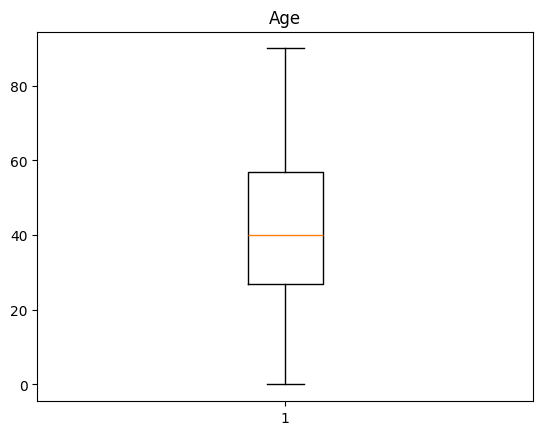

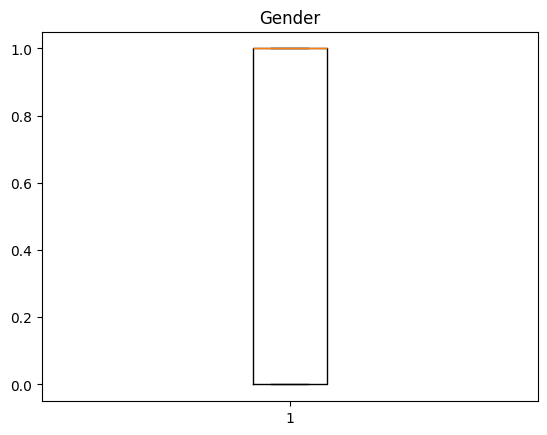

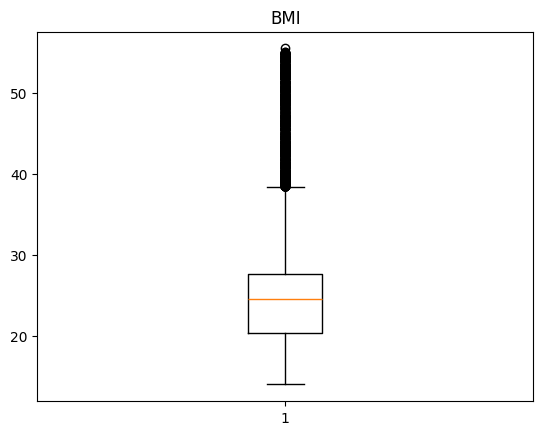

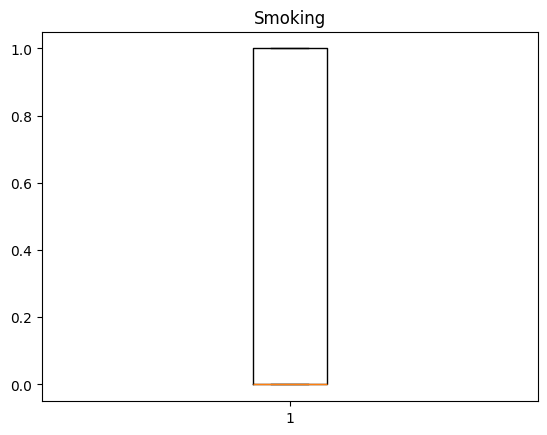

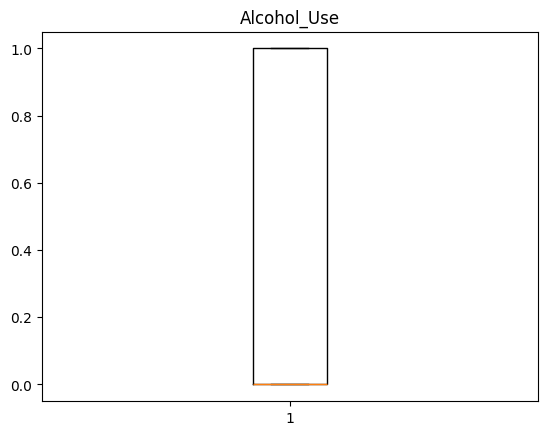

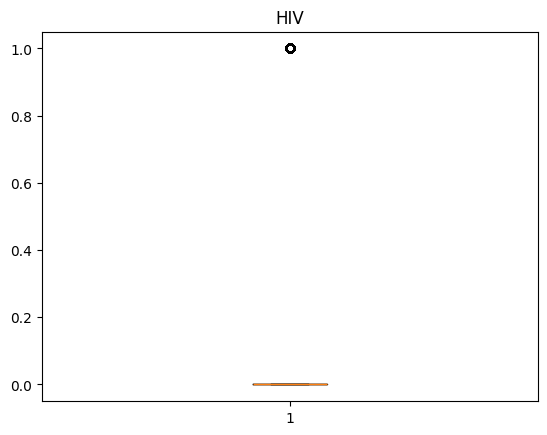

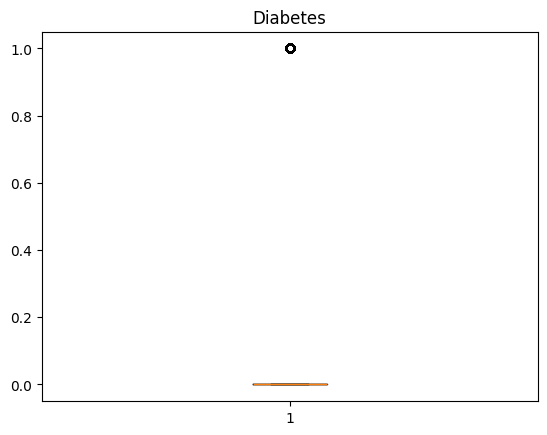

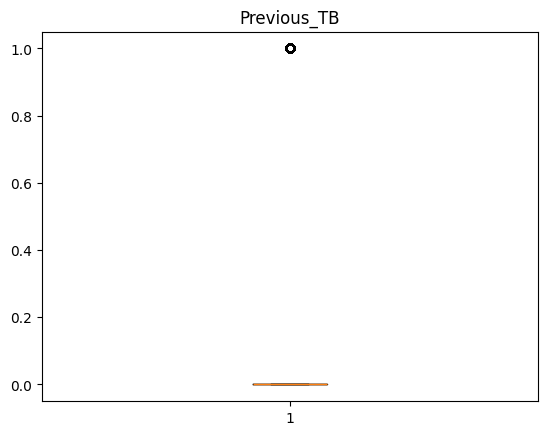

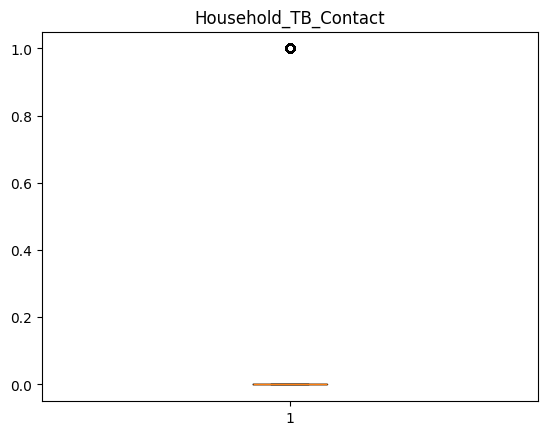

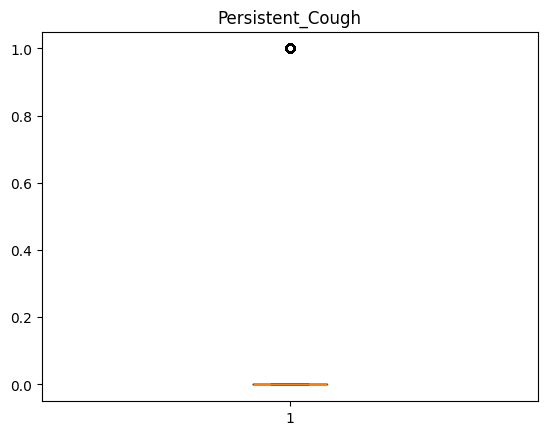

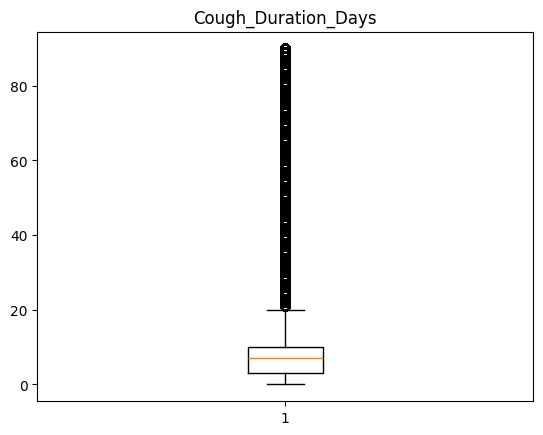

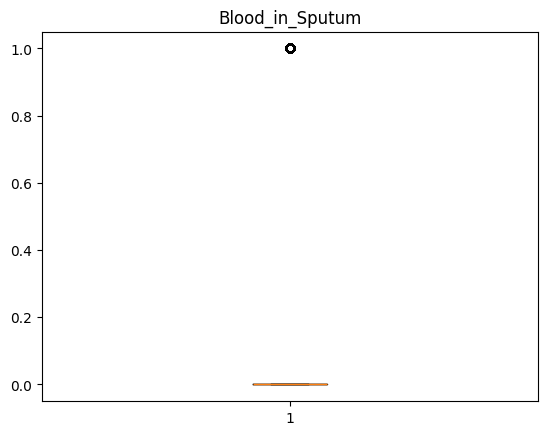

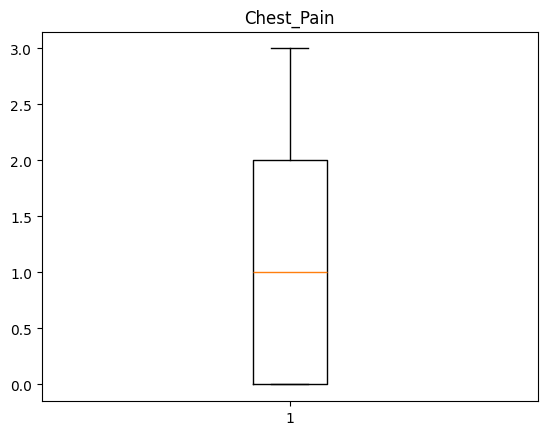

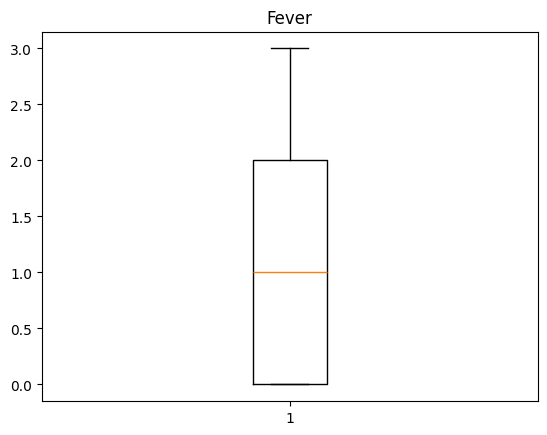

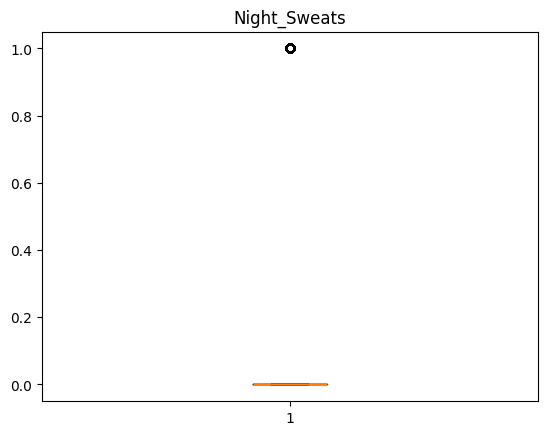

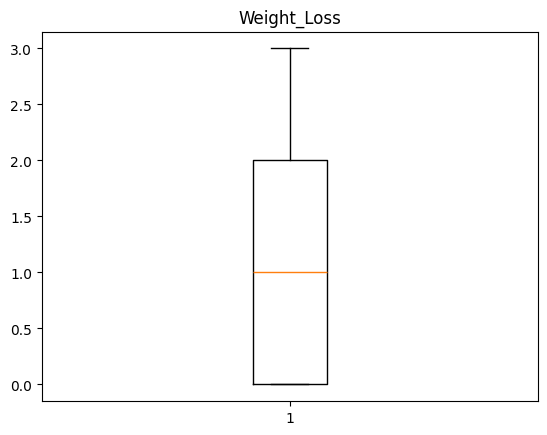

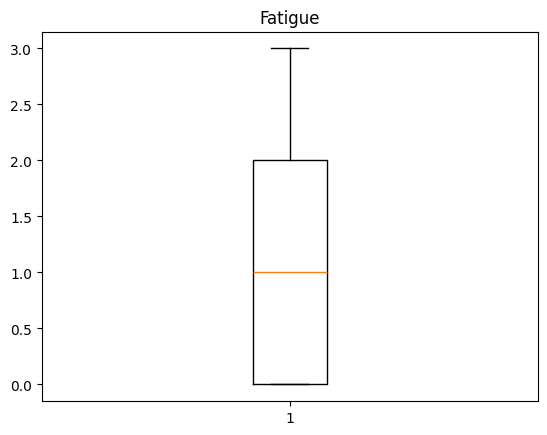

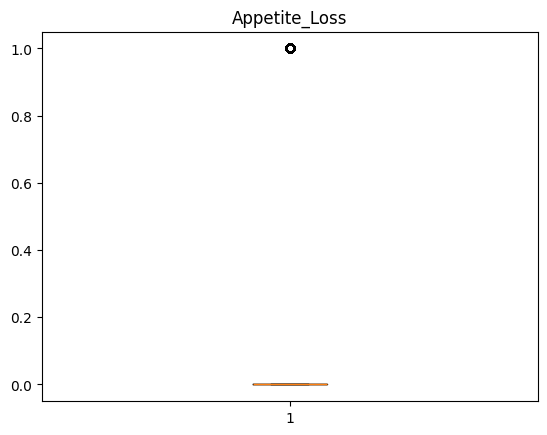

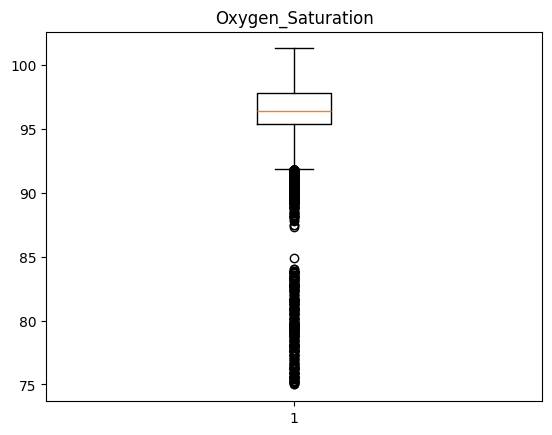

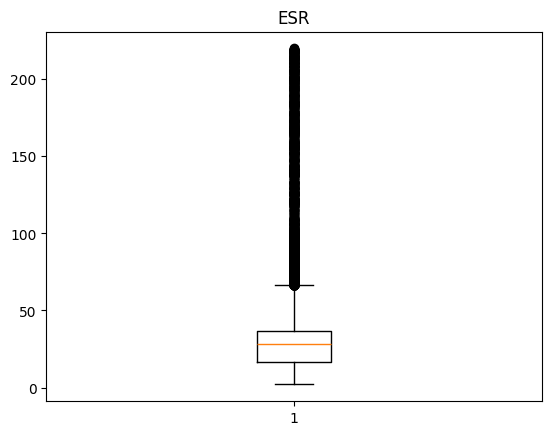

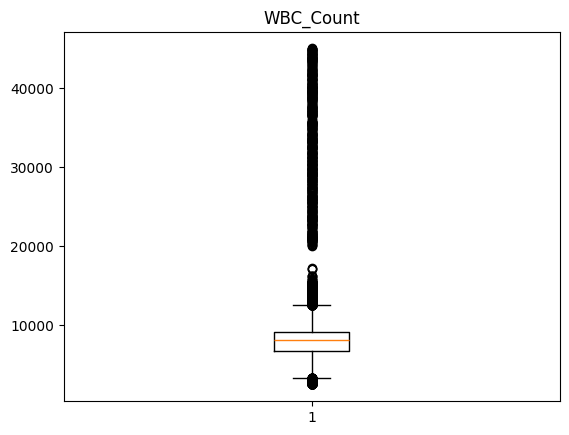

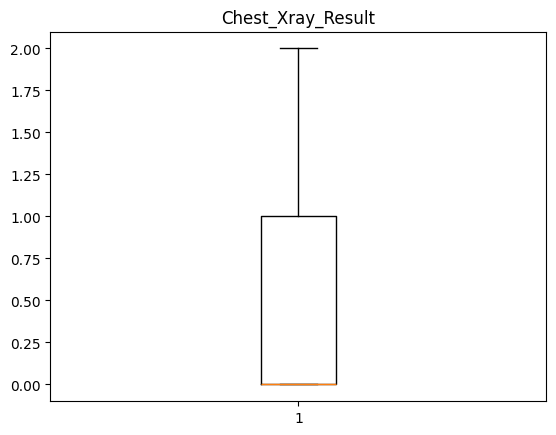

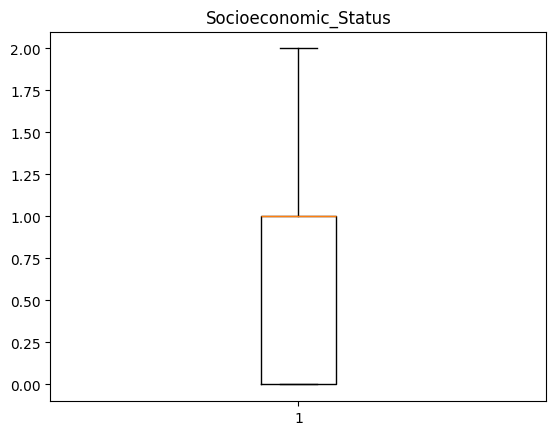

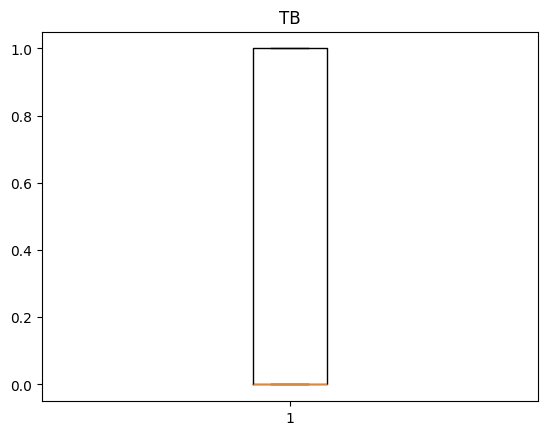

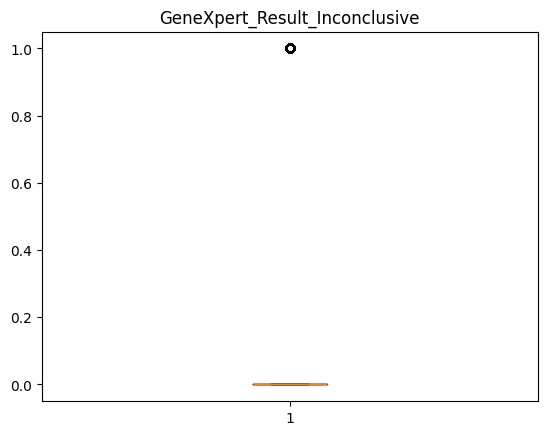

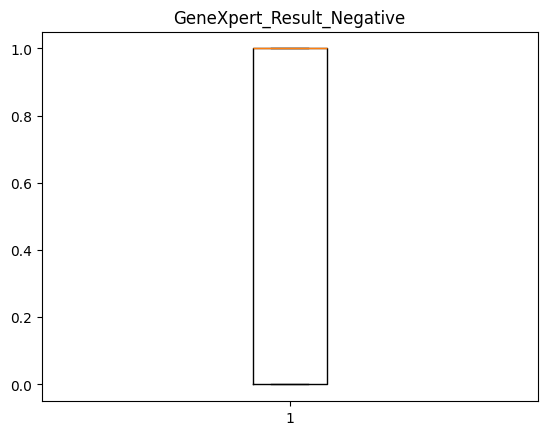

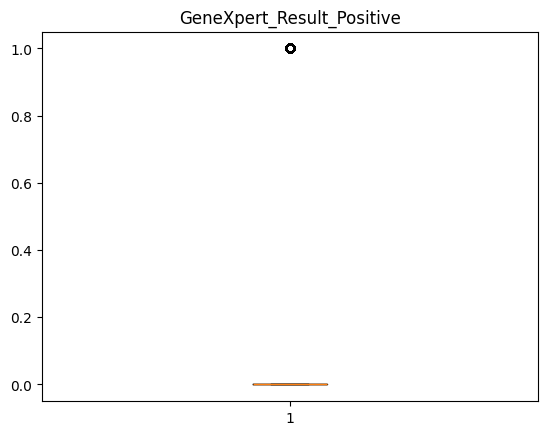

In [23]:
for col in df.columns:
    plt.title(col)
    plt.boxplot(df[col])
    plt.show()

In [24]:
bmi_q1 = df['BMI'].quantile(.25)
bmi_q3 = df['BMI'].quantile(.75)
bmi_iqr = bmi_q3 - bmi_q1

bmi_lw = bmi_q1 - 1.5 * bmi_iqr
bmi_uw = bmi_q3 + 1.5 * bmi_iqr

print(bmi_lw,bmi_uw)

9.599999999999994 38.400000000000006


In [25]:
df = df[(df['BMI'] >= 14 ) & (df['BMI'] <= 50)]

In [26]:
print(df['Cough_Duration_Days'].max())
print(df['Cough_Duration_Days'].min())

90
0


In [27]:
print(df['Oxygen_Saturation'].min())
print(df['Oxygen_Saturation'].max())

75.0
101.3


In [28]:
df = df[(df['Oxygen_Saturation'] >= 80) & (df['Oxygen_Saturation'] <= 100)]

In [29]:
print(df['ESR'].max())
print(df['ESR'].min())

219.9
2.0


In [30]:
df = df[df['ESR']<= 150]

In [31]:
print(df['WBC_Count'].min())
print(df['WBC_Count'].max())

2500.0
44986.0


In [32]:
df = df[(df['WBC_Count'] >= 3500) & (df['WBC_Count'] <= 25000)]

In [33]:
df.shape

(57542, 27)

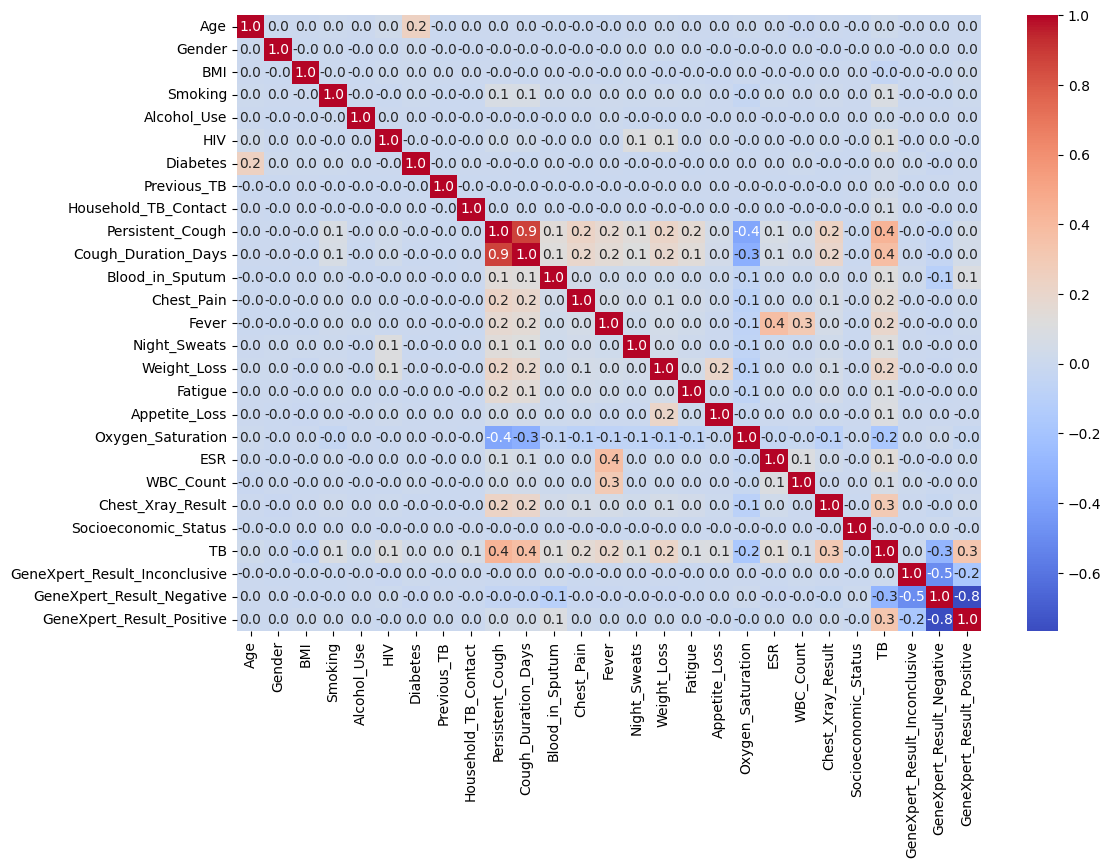

In [34]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(),fmt=".1f",annot=True,cmap="coolwarm")
plt.show()

In [35]:
(df.corr()['TB'])

Age                              0.023672
Gender                           0.003731
BMI                             -0.041967
Smoking                          0.084848
Alcohol_Use                      0.022725
HIV                              0.104664
Diabetes                         0.035913
Previous_TB                      0.035995
Household_TB_Contact             0.061344
Persistent_Cough                 0.427016
Cough_Duration_Days              0.375933
Blood_in_Sputum                  0.120925
Chest_Pain                       0.152678
Fever                            0.196489
Night_Sweats                     0.122784
Weight_Loss                      0.208521
Fatigue                          0.094794
Appetite_Loss                    0.097761
Oxygen_Saturation               -0.168659
ESR                              0.138608
WBC_Count                        0.062867
Chest_Xray_Result                0.297488
Socioeconomic_Status            -0.004471
TB                               1

In [36]:
x = df.drop('TB',axis=1)
y = df['TB']

In [37]:
y.value_counts(normalize=True)

TB
0    0.549373
1    0.450627
Name: proportion, dtype: float64

In [38]:
x_train,x_test,y_train,y_test = train_test_split(x,y,random_state=4,stratify=y,test_size=.25)

In [39]:
smt = SMOTETomek(random_state=42)
x_train,y_train = smt.fit_resample(x_train,y_train)

In [40]:
y_train.value_counts()

TB
1    20498
0    20498
Name: count, dtype: int64

In [41]:
scaler = StandardScaler()
x_train_scaler = scaler.fit_transform(x_train)
x_test_scaler =scaler.transform(x_test)

In [42]:
tree = DecisionTreeClassifier(min_samples_split=5,max_depth=17)
tree.fit(x_train,y_train)
tree_pred = tree.predict(x_test)

In [43]:
print(classification_report(y_test,tree_pred))
print(confusion_matrix(y_test,tree_pred))

              precision    recall  f1-score   support

           0       0.75      0.79      0.77      7903
           1       0.73      0.68      0.71      6483

    accuracy                           0.74     14386
   macro avg       0.74      0.74      0.74     14386
weighted avg       0.74      0.74      0.74     14386

[[6281 1622]
 [2068 4415]]


In [44]:
knn = KNeighborsClassifier(n_neighbors=25)
knn.fit(x_train_scaler,y_train)
knn_pred = knn.predict(x_test_scaler)

In [45]:
print(classification_report(y_test,knn_pred))
print(confusion_matrix(y_test,knn_pred))

              precision    recall  f1-score   support

           0       0.80      0.84      0.82      7903
           1       0.79      0.74      0.76      6483

    accuracy                           0.79     14386
   macro avg       0.79      0.79      0.79     14386
weighted avg       0.79      0.79      0.79     14386

[[6650 1253]
 [1712 4771]]


In [46]:
print(classification_report(y_train,knn.predict(x_train_scaler)))
print(confusion_matrix(y_train,knn.predict(x_train_scaler)))

              precision    recall  f1-score   support

           0       0.77      0.86      0.82     20498
           1       0.84      0.75      0.79     20498

    accuracy                           0.80     40996
   macro avg       0.81      0.80      0.80     40996
weighted avg       0.81      0.80      0.80     40996

[[17683  2815]
 [ 5208 15290]]


In [47]:
rand = RandomForestClassifier(n_estimators=400,min_samples_split=7)
rand.fit(x_train,y_train)
rand_pred = rand.predict(x_test)

In [48]:
print(classification_report(y_test,rand_pred))
print(confusion_matrix(y_test,rand_pred))

              precision    recall  f1-score   support

           0       0.82      0.84      0.83      7903
           1       0.79      0.77      0.78      6483

    accuracy                           0.81     14386
   macro avg       0.81      0.80      0.80     14386
weighted avg       0.81      0.81      0.81     14386

[[6614 1289]
 [1489 4994]]


In [49]:
print(classification_report(y_train,rand.predict(x_train)))
print(confusion_matrix(y_train,rand.predict(x_train)))

              precision    recall  f1-score   support

           0       0.97      0.96      0.96     20498
           1       0.96      0.97      0.96     20498

    accuracy                           0.96     40996
   macro avg       0.96      0.96      0.96     40996
weighted avg       0.96      0.96      0.96     40996

[[19637   861]
 [  635 19863]]


In [50]:
xgb = XGBClassifier()
xgb.fit(x_train,y_train)
xgb_pred = xgb.predict(x_test)

In [51]:
print(classification_report(y_test,xgb_pred))
print(confusion_matrix(y_test,xgb_pred))

              precision    recall  f1-score   support

           0       0.82      0.83      0.83      7903
           1       0.79      0.77      0.78      6483

    accuracy                           0.81     14386
   macro avg       0.80      0.80      0.80     14386
weighted avg       0.81      0.81      0.81     14386

[[6583 1320]
 [1465 5018]]


In [52]:
print(classification_report(y_train,xgb.predict(x_train)))
print(confusion_matrix(y_train,xgb.predict(x_train)))

              precision    recall  f1-score   support

           0       0.89      0.91      0.90     20498
           1       0.91      0.89      0.90     20498

    accuracy                           0.90     40996
   macro avg       0.90      0.90      0.90     40996
weighted avg       0.90      0.90      0.90     40996

[[18625  1873]
 [ 2220 18278]]


In [53]:
logi = LogisticRegression( penalty='l2',C=0.01, solver='lbfgs', max_iter=1000)
logi.fit(x_train_scaler,y_train)
logi_pred = logi.predict(x_test_scaler)

In [54]:
print(classification_report(y_test,logi_pred))
print(confusion_matrix(y_test,logi_pred))

              precision    recall  f1-score   support

           0       0.82      0.82      0.82      7903
           1       0.78      0.78      0.78      6483

    accuracy                           0.80     14386
   macro avg       0.80      0.80      0.80     14386
weighted avg       0.80      0.80      0.80     14386

[[6508 1395]
 [1413 5070]]


In [55]:
print(classification_report(y_train,logi.predict(x_train_scaler)))
print(confusion_matrix(y_train,logi.predict(x_train_scaler)))

              precision    recall  f1-score   support

           0       0.78      0.84      0.81     20498
           1       0.82      0.76      0.79     20498

    accuracy                           0.80     40996
   macro avg       0.80      0.80      0.80     40996
weighted avg       0.80      0.80      0.80     40996

[[17180  3318]
 [ 4945 15553]]


In [56]:
len(x_train.columns)

26

In [57]:
x_train.shape[1]

26

In [58]:
model = Sequential([
    Dense(units=64, activation='relu',input_shape = (x_train.shape[1],)),
    # Dropout(0.3),
    # Dense(units=64,activation='relu'),
    Dropout(0.3),
    Dense(units=32,activation='relu'),
    Dropout(0.2),
    Dense(units=16,activation='relu'),
    Dense(units=1,activation='sigmoid')
])

c:\Users\kripank\Desktop\fast API\env\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [59]:
model.compile(optimizer= Adam(learning_rate=0.0005),loss='binary_crossentropy',metrics=['accuracy'])

In [60]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)


In [61]:
history = model.fit(x_train_scaler,y_train,validation_split=0.2,epochs=100,batch_size=64,callbacks=[early_stop])

Epoch 1/100
513/513 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7625 - loss: 0.5016 - val_accuracy: 0.7009 - val_loss: 0.6675
Epoch 2/100
513/513 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8117 - loss: 0.4326 - val_accuracy: 0.7074 - val_loss: 0.6838
Epoch 3/100
513/513 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8156 - loss: 0.4252 - val_accuracy: 0.6994 - val_loss: 0.7227
Epoch 4/100
513/513 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8174 - loss: 0.4202 - val_accuracy: 0.7021 - val_loss: 0.6904
Epoch 5/100
513/513 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8183 - loss: 0.4179 - val_accuracy: 0.7022 - val_loss: 0.6927
Epoch 6/100
513/513 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8214 - loss: 0.4132 - val_accuracy: 0.6950 - val_loss: 0.7153


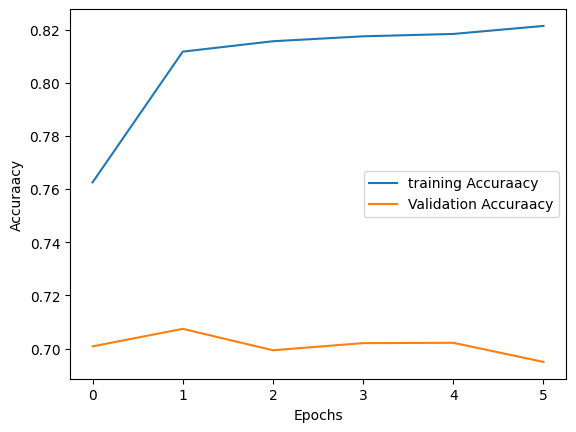

In [62]:
plt.plot(history.history['accuracy'], label = 'training Accuraacy')
plt.plot(history.history['val_accuracy'], label = 'Validation Accuraacy')
plt.xlabel('Epochs')
plt.ylabel('Accuraacy')
plt.legend()
plt.show()

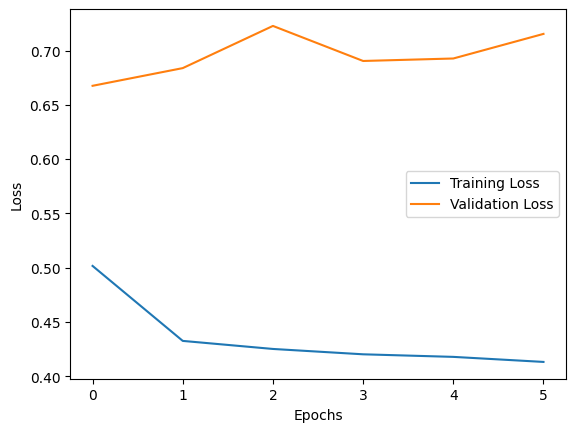

In [63]:
plt.plot(history.history['loss'], label = 'Training Loss')
plt.plot(history.history['val_loss'], label = 'Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [64]:
test_loss, test_accuracy = model.evaluate(x_test_scaler,y_test)
print(f"Test accuracy: {test_accuracy * 100:.2f}%")

450/450 ━━━━━━━━━━━━━━━━━━━━ 0s 967us/step - accuracy: 0.8070 - loss: 0.4351
Test accuracy: 80.70%


In [65]:
ann_pred = model.predict(x_test_scaler)


450/450 ━━━━━━━━━━━━━━━━━━━━ 0s 707us/step


In [66]:
ann_pred = (ann_pred > 0.5).astype(int)


In [67]:
print(classification_report(y_test,ann_pred))
print(confusion_matrix(y_test,ann_pred))

              precision    recall  f1-score   support

           0       0.83      0.82      0.82      7903
           1       0.78      0.79      0.79      6483

    accuracy                           0.81     14386
   macro avg       0.81      0.81      0.81     14386
weighted avg       0.81      0.81      0.81     14386

[[6483 1420]
 [1356 5127]]


In [68]:
ann_train_pred = model.predict(x_train_scaler)
ann_train_pred = (ann_train_pred > 0.5).astype(int)
print(classification_report(y_train,ann_train_pred))
print(confusion_matrix(y_train,ann_train_pred))

1282/1282 ━━━━━━━━━━━━━━━━━━━━ 1s 630us/step
              precision    recall  f1-score   support

           0       0.78      0.83      0.80     20498
           1       0.82      0.76      0.79     20498

    accuracy                           0.80     40996
   macro avg       0.80      0.80      0.80     40996
weighted avg       0.80      0.80      0.80     40996

[[17089  3409]
 [ 4901 15597]]


In [70]:
dump(model,'TB_model.joblib')

['TB_model.joblib']

In [ ]:
x_train_scaler[[2]]

array([[-0.15786188, -1.04530042, -0.89567614, -0.67242224, -0.59282838,
        -0.25156425, -0.32598444, -0.23721563,  2.88948868, -0.58042979,
        -0.50997843, -0.23577811,  0.93691478,  0.81932214, -0.37460632,
         0.90686194, -1.10919217,  2.18664425,  1.77679857, -0.1689159 ,
        -0.47574009, -0.85794037,  0.20749159, -0.34163848,  0.70196962,
        -0.54395191]])

In [88]:
model.predict(x_train_scaler[[11]])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


array([[0.9241161]], dtype=float32)

In [89]:
y_train[11]

np.int64(1)